In [1]:
import numpy as np

ratings = np.loadtxt("ml-32m/ratings.csv", delimiter = ",", skiprows= 1)

#ratings = ratings[:1000000]

In [2]:
cols = ['userId', 'movieId', 'rating', 'timestamp']

col_to_ind = {col:ind for ind,col in enumerate(cols)}

In [3]:
users_to_index = {}
index_to_users = []

movies_to_index = {}
index_to_movies = []

data_by_users = []
data_by_movies = []

In [4]:
len(ratings[:,col_to_ind["userId"]])

32000204

In [5]:
index_to_users = np.unique(ratings[:,col_to_ind["userId"]]).tolist()
users_to_index = {user:index for index,user in enumerate(index_to_users)}


index_to_movies = np.unique(ratings[:,col_to_ind["movieId"]]).tolist()
movies_to_index = {movie:index for index,movie in enumerate(index_to_movies)}

In [6]:
def process_user_ratings(ratings_arr,index_to_users):
  data_by_users =  [[] for _ in range(len(index_to_users))]

  for row in ratings_arr:
    user = row[col_to_ind["userId"]]
    movie = row[col_to_ind["movieId"]]
    rating = row[col_to_ind["rating"]]

    data_by_users[users_to_index[user]].append((movies_to_index[movie],rating))

  return data_by_users


In [7]:
def process_movie_ratings(ratings_arr,index_to_movies):
  data_by_movies =  [[] for _ in range(len(index_to_movies))]

  for row in ratings_arr:
    user = row[col_to_ind["userId"]]
    movie = row[col_to_ind["movieId"]]
    rating = row[col_to_ind["rating"]]

    data_by_movies[movies_to_index[movie]].append((users_to_index[user],rating))

  return data_by_movies


In [8]:
# splitting into train and test

import random
random.seed(42)

CUTOFF = 0.7

random_nums = [random.uniform(0,1) > CUTOFF for i in range(ratings.shape[0])]

test_locs = [i for i,j in enumerate(random_nums) if j]
train_locs = [i for i,j in enumerate(random_nums) if not j]

print(len(test_locs))
print(len(train_locs))

ratings_test = ratings[test_locs]
ratings_train = ratings[train_locs]

9595382
22404822


In [9]:
data_by_users_train = process_user_ratings(ratings_train, index_to_users)

data_by_users_test = process_user_ratings(ratings_test, index_to_users )


In [10]:
data_by_movies_test = process_movie_ratings(ratings_test, index_to_movies)
data_by_movies_train =  process_movie_ratings(ratings_train, index_to_movies)

## Loading features, using tags 

In [11]:
import csv 

movie_db = []


with open("ml-32m/movies.csv") as f: 
    reader = csv.reader(f)
    
    headers = next(reader)
    
    for movie_id, title, genres in reader: 
        movie_db.append((movie_id,title,genres))
                

In [23]:
index_to_genres = []

for movie_id, title, genres in movie_db: 
    for genre in genres.split("|"): 
                if genre not in index_to_genres: 
                    index_to_genres.append(genre)
                    
genre_to_indexes = {g: i for i,g in enumerate(index_to_genres)}

movie_genres = np.zeros((len(index_to_movies), len(index_to_genres)))  # final one hot encoded array of movies * tags
for movie_id, title, genres in movie_db: 
    if int(movie_id) in movies_to_index: 
        for genre in genres.split("|"): 
            movie_genres[movies_to_index[int(movie_id)], genre_to_indexes[genre]] = 1 
        
movie_genres

array([[1., 1., 1., ..., 0., 0., 0.],
       [1., 0., 1., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [1., 0., 0., ..., 0., 0., 0.]], shape=(84432, 20))

In [30]:
movie_genres.sum(axis=1).min()

movie_genres.sum()

np.float64(149285.0)

In [35]:
import numpy as np

N_ITER = 20
lamb = 0.09
gamma = 0.1
tau = 0.9
VERBOSITY = 1
K = len(index_to_genres)

user_biases = np.zeros(len(data_by_users_train))
movies_biases = np.zeros(len(data_by_movies_train))

U = np.random.normal(size = (len(data_by_users_train),K))
V = movie_genres

In [36]:
train_rmses = []
test_rmses = []
test_losses = []
train_losses = []

for _ in range(N_ITER):

  # update bias
  for i, item_ratings in enumerate(data_by_users_train):
    bias = 0
    item_counter = 0
    for (n,r) in item_ratings:
      bias += lamb * (r - movies_biases[n])
      item_counter += 1
    bias = bias / (lamb * item_counter + gamma)
    user_biases[i] = bias

  for m, item_ratings in enumerate(data_by_users_train):
    item_counter = 0
    u_comp1 = np.zeros([K,K])
    u_comp2 = np.zeros(K)
    for (n,r) in item_ratings:
      u_comp1 += lamb * np.outer(V[n],V[n])
      u_comp2 += lamb * (V[n] * (r - user_biases[m] - movies_biases[n]))
      item_counter += 1
    u_comp1 = u_comp1 + tau * np.identity(K)
    U[m] = np.linalg.solve(u_comp1,u_comp2)

  for i, item_ratings in enumerate(data_by_movies_train):
    bias = 0
    item_counter = 0
    for (n,r) in item_ratings:
      bias += lamb * (r - user_biases[n])
      item_counter += 1
    bias = bias / (lamb * item_counter + gamma)
    movies_biases[i] = bias

  for n, item_ratings in enumerate(data_by_movies_train):
    item_counter = 0
    v_comp1 = np.zeros([K,K])
    v_comp2 = np.zeros(K)
    for (m,r) in item_ratings:
      v_comp1 += lamb * np.outer(U[m],U[m])
      v_comp2 += lamb * (U[m] * (r - user_biases[m] - movies_biases[n]))
      item_counter += 1
    v_comp1 = v_comp1 + tau * np.identity(K)
    V[n] = np.linalg.solve(v_comp1,v_comp2)

  error = 0
  loss = 0
  items_count = 0
  for m,ratings in enumerate(data_by_users_train):
    for (n,r) in ratings:
      pred = (U[m] @ V[n]) + user_biases[m] + movies_biases[n]
      true = r
      error_ = (pred - true)**2
      error += error_
      loss += error_
      items_count += 1
  u_loss_comp = 0
  v_loss_comp = 0
  for u in U:
    u_loss_comp += u @ u
  for v in V:
    v_loss_comp += v @ v
  train_RMSE = (error/items_count) ** (1/2)
  train_rmses.append(train_RMSE)
  loss += (u_loss_comp + v_loss_comp) * tau + (sum(user_biases**2) + sum(movies_biases**2)) * gamma
  train_loss = loss/items_count
  train_losses.append(train_loss)


  error = 0
  loss = 0
  items_count = 0
  for m,ratings in enumerate(data_by_users_test):
    for (n,r) in ratings:
      pred = (U[m] @ V[n]) + user_biases[m] + movies_biases[n]
      true = r
      error_ = (pred - true)**2
      error += error_
      loss += error_
      items_count += 1
  u_loss_comp = 0
  v_loss_comp = 0
  for u in U:
    u_loss_comp += u @ u
  for v in V:
    v_loss_comp += v @ v
  test_RMSE = (error/items_count) ** (1/2)
  test_rmses.append(test_RMSE)
  loss += (u_loss_comp + v_loss_comp) * tau + (sum(user_biases**2) + sum(movies_biases**2)) * gamma
  test_loss = loss/items_count
  test_losses.append(test_loss)

  if _ % VERBOSITY == 0:
    print(f"Round {_}:  Train RMSE: {train_RMSE} Test RMSE: {test_RMSE}")
    print(f"Round {_}:  Train loss: {train_loss} Test loss: {test_loss}")
print(f"After training:  Train RMSE: {train_RMSE} Test RMSE: {test_RMSE}")
print(f"After training:  Train loss: {train_loss} Test loss: {test_loss}")

Round 0:  Train RMSE: 0.7217598199695012 Test RMSE: 0.815022361218803
Round 0:  Train loss: 0.5392266375323166 Test loss: 0.7069664450052238
Round 1:  Train RMSE: 0.6907185919487885 Test RMSE: 0.7979810162708547
Round 1:  Train loss: 0.4934830599490689 Test loss: 0.6750457480489386
Round 2:  Train RMSE: 0.6791215671317701 Test RMSE: 0.7920055220385831
Round 2:  Train loss: 0.4773102241522434 Test loss: 0.6648752070759605
Round 3:  Train RMSE: 0.673815029321578 Test RMSE: 0.7895222505843653
Round 3:  Train loss: 0.4698732450039506 Test loss: 0.6603464290861566
Round 4:  Train RMSE: 0.6709841758856433 Test RMSE: 0.7883958588441214
Round 4:  Train loss: 0.46581779286931146 Test loss: 0.6579887849237418
Round 5:  Train RMSE: 0.6693186908645848 Test RMSE: 0.7878523287556567
Round 5:  Train loss: 0.4633488016034059 Test loss: 0.656579275648863
Round 6:  Train RMSE: 0.6682694225242338 Test RMSE: 0.787586058242154
Round 6:  Train loss: 0.46172037272987776 Test loss: 0.6556345571876255
Round 7:

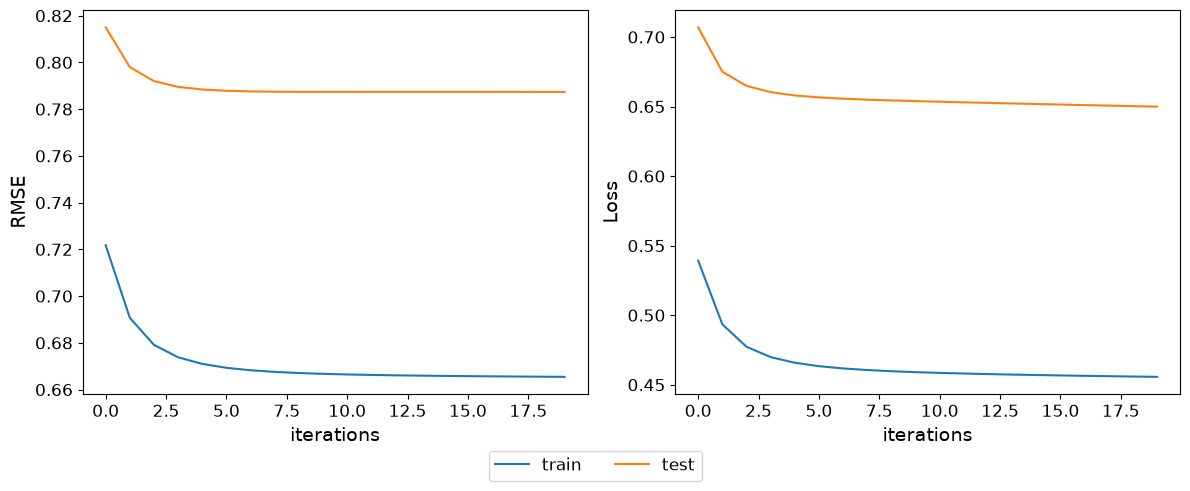

In [ ]:
from matplotlib import pyplot as plt

plt.rcParams['axes.labelsize'] = 14
plt.rcParams['xtick.labelsize'] = 12
plt.rcParams['ytick.labelsize'] = 12

fig,axs = plt.subplots(1,2, figsize = (12,5))

axs[0].plot(range(N_ITER), train_rmses, label = "train")
axs[0].plot(range(N_ITER), test_rmses, label = "test")
axs[0].set_ylabel("RMSE")
axs[0].set_xlabel("iterations")

axs[1].plot(range(N_ITER), train_losses, label = "train")
axs[1].plot(range(N_ITER), test_losses, label = "test")
axs[1].set_ylabel("Loss")
axs[1].set_xlabel("iterations")


handles, labels = axs[1].get_legend_handles_labels()

fig.legend(handles, labels, loc='lower center', ncol=2, bbox_to_anchor=(0.5, 0.01), fontsize = 12)

plt.tight_layout()
plt.subplots_adjust(bottom=0.2)

plt.savefig("images/loss_progression_plot_fetures.svg")

plt.show()

In [38]:
np.savez("embeddings.npz", U = U, V = V, user_biases = user_biases, movies_biases = movies_biases, index_to_users = index_to_users, index_to_movies = index_to_movies)